In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

splits = pd.read_csv(r"D:\AgriVision\data\splits.csv")
train_df = splits[splits.split == "train"]
val_df = splits[splits.split == "val"]
test_df = splits[splits.split == "test"]

classes = sorted(splits["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

IMG_SIZE, BATCH = 224, 32

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label   # no /255 here: MobileNetV2 preprocessing is inside the model

def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["path"].values, frame["label"].map(class_to_idx).values))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

y_train = train_df["label"].map(class_to_idx).values
w = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(w))
print(classes)

['BrownRust', 'Healthy', 'Mildew', 'Septoria', 'YellowRust']


In [2]:
from tensorflow import keras
from tensorflow.keras import layers

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])

base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


baseline test accuracy: 0.6600
fine-tuned test accuracy: 0.6467

Best model: baseline (0.6600)

              precision    recall  f1-score   support

   BrownRust       0.60      0.63      0.62        19
     Healthy       0.62      0.95      0.75        19
      Mildew       0.74      0.58      0.65        24
    Septoria       0.67      0.77      0.71        52
  YellowRust       0.68      0.42      0.52        36

    accuracy                           0.66       150
   macro avg       0.66      0.67      0.65       150
weighted avg       0.67      0.66      0.65       150



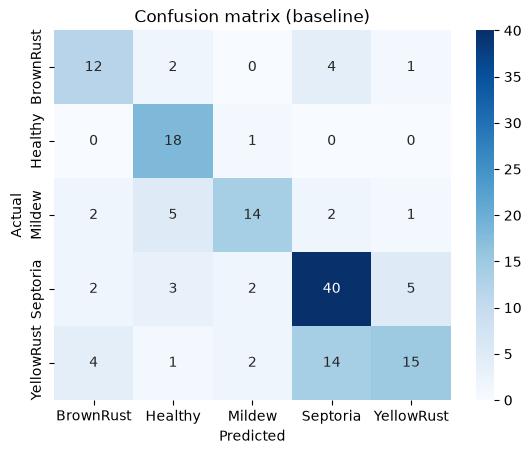

In [8]:
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix

splits = pd.read_csv(r"D:\AgriVision\data\splits.csv")
test_df = splits[splits.split == "test"]
classes = ["BrownRust", "Healthy", "Mildew", "Septoria", "YellowRust"]
c2i = {c: i for i, c in enumerate(classes)}

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    return img, label

test_ds = (tf.data.Dataset.from_tensor_slices(
               (test_df["path"].values, test_df["label"].map(c2i).values))
           .map(load_image).batch(32))

results = {}
for name, path in [("baseline", r"D:\AgriVision\models\leaf_model.keras"),
                   ("fine-tuned", r"D:\AgriVision\models\leaf_model_ft.keras")]:
    m = keras.models.load_model(path)
    y_true, y_pred = [], []
    for x, y in test_ds:
        y_true.extend(y.numpy())
        y_pred.extend(np.argmax(m.predict(x, verbose=0), axis=1))
    acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
    results[name] = (acc, y_true, y_pred)
    print(f"{name} test accuracy: {acc:.4f}")

best = max(results, key=lambda k: results[k][0])
acc, y_true, y_pred = results[best]
print(f"\nBest model: {best} ({acc:.4f})\n")
print(classification_report(y_true, y_pred, target_names=classes))

sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix ({best})")
plt.show()

In [3]:
history = model.fit(train_ds, validation_data=val_ds, epochs=10,
                    class_weight=class_weights)

Epoch 1/10


d:\AgriVision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 ━━━━━━━━━━━━━━━━━━━━ 73s 3s/step - accuracy: 0.2632 - loss: 1.7135 - val_accuracy: 0.4467 - val_loss: 1.3534
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 51s 2s/step - accuracy: 0.4177 - loss: 1.3460 - val_accuracy: 0.5467 - val_loss: 1.1725
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.5093 - loss: 1.1918 - val_accuracy: 0.5667 - val_loss: 1.1528
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.5322 - loss: 1.0596 - val_accuracy: 0.5933 - val_loss: 1.0535
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.5651 - loss: 0.9970 - val_accuracy: 0.6000 - val_loss: 1.0216
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.6009 - loss: 0.9582 - val_accuracy: 0.6467 - val_loss: 0.9429
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.6309 - loss: 0.9135 - val_accuracy: 0.6333 - val_loss: 0.9555
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step - accuracy: 0.6466 - loss: 0.8440 - val_accuracy: 0.6600 - val_loss: 0.8864
Epo

In [4]:
loss, acc = model.evaluate(test_ds)
print("Test accuracy:", acc)
model.save(r"D:\AgriVision\models\leaf_model.keras")

5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.6600 - loss: 0.9382
Test accuracy: 0.6600000262260437


In [5]:
base.trainable = True
for layer in base.layers[:-30]:      # keep the early layers frozen
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                      restore_best_weights=True)

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=15,
                       class_weight=class_weights, callbacks=[early])

loss, acc = model.evaluate(test_ds)
print("Test accuracy after fine-tuning:", acc)
model.save(r"D:\AgriVision\models\leaf_model_ft.keras")

Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 108s 4s/step - accuracy: 0.5579 - loss: 1.1282 - val_accuracy: 0.6800 - val_loss: 0.8427
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 123s 3s/step - accuracy: 0.5823 - loss: 1.0307 - val_accuracy: 0.6867 - val_loss: 0.8290
Epoch 3/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - accuracy: 0.5908 - loss: 1.0129 - val_accuracy: 0.6800 - val_loss: 0.8237
Epoch 4/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.6166 - loss: 0.9211 - val_accuracy: 0.6733 - val_loss: 0.8187
Epoch 5/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.6466 - loss: 0.8678 - val_accuracy: 0.6933 - val_loss: 0.8175
Epoch 6/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 89s 3s/step - accuracy: 0.6695 - loss: 0.8375 - val_accuracy: 0.7000 - val_loss: 0.8135
Epoch 7/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.6538 - loss: 0.8218 - val_accuracy: 0.7000 - val_loss: 0.8109
Epoch 8/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.6853 - loss: 0.7888 - val_accuracy: 0.6933 - val_los

              precision    recall  f1-score   support

   BrownRust       0.55      0.63      0.59        19
     Healthy       0.55      0.95      0.69        19
      Mildew       0.79      0.46      0.58        24
    Septoria       0.69      0.69      0.69        52
  YellowRust       0.66      0.53      0.58        36

    accuracy                           0.64       150
   macro avg       0.64      0.65      0.63       150
weighted avg       0.66      0.64      0.63       150



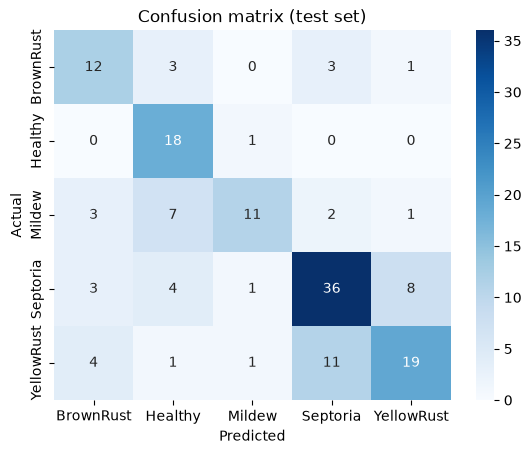

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_true, y_pred = [], []
for x, y in test_ds:
    p = model.predict(x, verbose=0)
    y_true.extend(y.numpy())
    y_pred.extend(np.argmax(p, axis=1))

print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (test set)")
plt.show()

In [7]:
from tensorflow import keras

base = next(l for l in model.layers if "mobilenet" in l.name.lower())
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                      restore_best_weights=True)

history_ft = model.fit(train_ds, validation_data=val_ds, epochs=8,
                       class_weight=class_weights, callbacks=[early])

loss, acc = model.evaluate(test_ds)
print("Test accuracy after fine-tuning:", acc)
model.save(r"D:\AgriVision\models\leaf_model_ft.keras")

Epoch 1/8


d:\AgriVision\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.6667 - loss: 0.8236 - val_accuracy: 0.6867 - val_loss: 0.8124
Epoch 2/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.7010 - loss: 0.7628 - val_accuracy: 0.6933 - val_loss: 0.7967
Epoch 3/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 56s 3s/step - accuracy: 0.6810 - loss: 0.7901 - val_accuracy: 0.6933 - val_loss: 0.7906
Epoch 4/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 70s 3s/step - accuracy: 0.6910 - loss: 0.7685 - val_accuracy: 0.6933 - val_loss: 0.7841
Epoch 5/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.7282 - loss: 0.7097 - val_accuracy: 0.7000 - val_loss: 0.7801
Epoch 6/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.7067 - loss: 0.7458 - val_accuracy: 0.7000 - val_loss: 0.7736
Epoch 7/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 61s 3s/step - accuracy: 0.7296 - loss: 0.6927 - val_accuracy: 0.7000 - val_loss: 0.7706
Epoch 8/8
22/22 ━━━━━━━━━━━━━━━━━━━━ 60s 3s/step - accuracy: 0.7525 - loss: 0.6766 - val_accuracy: 0.7000 - val_loss: 0.7555
5/5 ━━━━━━

Fine-tuned file found: [WindowsPath('D:/AgriVision/models/leaf_model_ft_old.keras.keras')]
baseline test accuracy: 0.66
fine-tuned test accuracy: 0.6467
Best model: baseline 0.66
              precision    recall  f1-score   support

   BrownRust       0.60      0.63      0.62        19
     Healthy       0.62      0.95      0.75        19
      Mildew       0.74      0.58      0.65        24
    Septoria       0.67      0.77      0.71        52
  YellowRust       0.68      0.42      0.52        36

    accuracy                           0.66       150
   macro avg       0.66      0.67      0.65       150
weighted avg       0.67      0.66      0.65       150



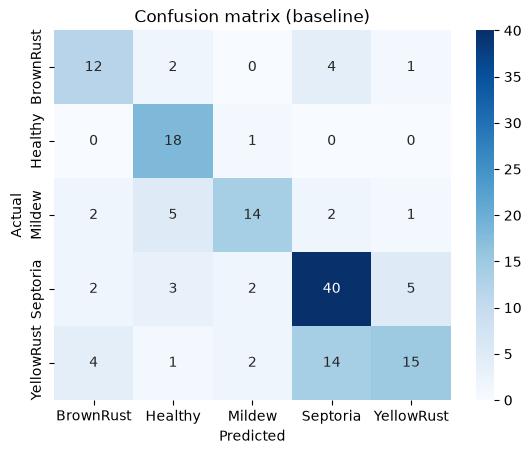

In [10]:
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix

MODELS = Path(r"D:\AgriVision\models")
baseline_path = MODELS / "leaf_model.keras"
ft_candidates = [p for p in MODELS.glob("*.keras") if "ft" in p.name.lower()]
print("Fine-tuned file found:", ft_candidates)

splits = pd.read_csv(r"D:\AgriVision\data\splits.csv")
test_df = splits[splits.split == "test"]
classes = ["BrownRust", "Healthy", "Mildew", "Septoria", "YellowRust"]
c2i = {c: i for i, c in enumerate(classes)}


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    return img, label


test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["path"].values, test_df["label"].map(c2i).values))
test_ds = test_ds.map(load_image).batch(32)

to_test = [("baseline", baseline_path)]
if ft_candidates:
    to_test.append(("fine-tuned", ft_candidates[0]))

results = {}
for name, path in to_test:
    model_i = keras.models.load_model(str(path))
    y_true, y_pred = [], []
    for x, y in test_ds:
        y_true.extend(y.numpy())
        y_pred.extend(np.argmax(model_i.predict(x, verbose=0), axis=1))
    acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
    results[name] = (acc, y_true, y_pred)
    print(name, "test accuracy:", round(acc, 4))

best = max(results, key=lambda k: results[k][0])
acc, y_true, y_pred = results[best]
print("Best model:", best, round(acc, 4))
print(classification_report(y_true, y_pred, target_names=classes))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (" + best + ")")
plt.show()